# Análisis del comportamiento de una aplicación bajo diferentes escenarios de despliegue

**Curso:** Principios y prácticas de Desarrollo de Software Orientado a Objetos
**Profesor:** Gabriel Rodrigo Pedraza Ferreira
**Integrantes:** Jhair Fernando Sánchez Ceballos (2221893), **[COMPLETAR: demás integrantes]**
**Repositorio:** https://github.com/jha1rs/proyecto-soft3

Este notebook descarga los resultados de JMeter desde el repositorio, los procesa y genera todas las tablas y gráficas. Se puede ejecutar completo en Google Colab con *Entorno de ejecución → Ejecutar todas*.

## 1. Introducción y objetivos

En este proyecto se desplegó una misma aplicación de varias formas y se midió cómo responde a distintas cargas. Los escenarios fueron:

| Escenario | Herramienta | Réplicas del backend |
|---|---|---|
| Una sola máquina | Docker Compose | 1 |
| Clúster de 1 nodo | Kubernetes (MicroK8s) | 1, 2 y 3 |
| Clúster de 2 nodos | Kubernetes (MicroK8s) | 1, 2 y 3 |
| Clúster de 3 nodos | Kubernetes (MicroK8s) | 1, 2 y 3 |

En cada configuración se generó carga con JMeter (10, 50, 100 y 200 usuarios concurrentes) y se registraron el **tiempo medio de respuesta** y el **throughput** (peticiones atendidas por segundo).

**Objetivo general:** analizar cómo el entorno de despliegue, el número de réplicas y el número de nodos afectan el rendimiento de la aplicación, en especial el escalado horizontal.

**Objetivos específicos:**

- Desplegar la aplicación con Docker Compose y en Kubernetes con 1, 2 y 3 nodos.
- Medir con JMeter el tiempo medio de respuesta y el throughput bajo varias cargas y números de réplicas.
- Comparar los escenarios, encontrar tendencias y cuellos de botella.
- Sacar conclusiones sobre escalabilidad y uso de recursos, y proponer recomendaciones.

## 2. Descripción de la aplicación

La aplicación parte del proyecto [bookstore-app](https://github.com/chaphe/bookstore-app) del profesor, una librería virtual hecha con microservicios. De ese proyecto se tomó solo el **servicio de catálogo de libros**, que cumple los requisitos del enunciado:

- **Backend:** API hecha en Java 17 con Spring Boot 3.2 y Spring Data JPA.
- **API REST:** todas las operaciones se hacen por HTTP con respuestas JSON.
- **Persistencia:** base de datos MySQL 8.0 con una tabla `Book`.
- **Cantidad de datos:** el script `db/init.sql` genera **10.000 libros** al crear la base.

Endpoints de la API:

| Método | Ruta | Qué hace |
|---|---|---|
| GET | `/api/libros?page=0&size=20` | Una página de libros ordenada por ISBN (agregado para las pruebas) |
| GET | `/api/libro/{isbn}` | Un libro por su ISBN (agregado para las pruebas) |
| GET | `/api/getlibros` | Todos los libros (original del profesor; no se usó en las pruebas porque devuelve los 10.000 registros) |
| POST / PUT | `/api/libro` | Crear o editar un libro |
| DELETE | `/api/deletelibro?ISBN=...` | Borrar un libro |

Recorrido de una petición en Kubernetes:

```
JMeter ──HTTP──▶ NodePort 30300 (vm1) ──▶ pod del backend (cualquier nodo) ──SQL──▶ pod de MySQL (vm1)
```

Cambios hechos al proyecto del profesor:

- Se dejaron solo el backend del catálogo y su base; se quitaron frontends, reseñas, tienda, envíos y RabbitMQ.
- Se agregaron los dos endpoints de consulta usados por JMeter. El listado paginado usa `Page` de Spring, que además de la página hace un `SELECT COUNT(*)` en cada petición.
- Se reemplazaron los 13 libros de ejemplo por un script que genera 10.000 libros dentro de MySQL. El mismo script se usa en Docker Compose (montado en `/docker-entrypoint-initdb.d`) y en Kubernetes (a través de un ConfigMap), así los datos son idénticos en todos los escenarios.
- Se desactivó el registro de consultas SQL en consola (`show-sql`), que bajo carga hacía más lenta la aplicación.

Así se ven los datos generados:

In [1]:
import os

# En Colab se descarga el repositorio. Si el notebook se abre dentro del repositorio, se usa tal cual.
if not os.path.exists("resultados"):
    !git clone -q https://github.com/jha1rs/proyecto-soft3.git
    %cd proyecto-soft3

In [2]:
import glob
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 1)

def mostrar(ruta, desde=None, hasta=None):
    # Imprime un archivo del repositorio (o un rango de lineas)
    lineas = open(ruta, encoding="utf-8").read().splitlines()
    print(f"# ---- {ruta} ----")
    print("\n".join(lineas[desde:hasta]))

mostrar("db/init.sql")

# ---- db/init.sql ----
-- Inicializacion completa de la base del catalogo: crea la base, la tabla Book
-- y genera 10.000 libros de prueba (ISBN 9790000000001 .. 9790000010000).
-- Lo usan Docker Compose (montando db/) y Kubernetes (ConfigMap mysql-catalog-init).

CREATE DATABASE IF NOT EXISTS `catalog-library`;
USE `catalog-library`;

CREATE TABLE IF NOT EXISTS Book (
    titulo VARCHAR(60),
    ISBN VARCHAR(60) PRIMARY KEY,
    autor VARCHAR(60),
    descripcion VARCHAR(250),
    valor VARCHAR(60),
    unidades INT
);

SET SESSION cte_max_recursion_depth = 10001;

INSERT INTO Book (titulo, ISBN, autor, descripcion, valor, unidades)
WITH RECURSIVE seq (n) AS (
    SELECT 1
    UNION ALL
    SELECT n + 1 FROM seq WHERE n < 10000
)
SELECT
    CONCAT(
        ELT(1 + MOD(n * 7, 12), 'El secreto', 'La sombra', 'El camino', 'La ciudad', 'El ultimo', 'La casa',
            'El jardin', 'La memoria', 'El viaje', 'La voz', 'El silencio', 'La noche'),
        ' ',
        ELT(1 + MOD(n * 11, 

In [3]:
# Muestra de una respuesta real de la API, tomada de los resultados de JMeter
muestra = pd.read_csv("resultados/k8s1n_1rep_100u_r1_vm.csv", nrows=2000)
print(muestra[["label", "responseCode", "bytes", "URL"]].drop_duplicates("label").to_string(index=False))

               label  responseCode  bytes                                                    URL
GET libros paginados           200   3934 http://192.168.56.11:30300/api/libros?page=349&size=20
  GET libro por ISBN           200    442     http://192.168.56.11:30300/api/libro/9790000005301


## 3. Infraestructura

Todo se montó con **VirtualBox** y **Vagrant** (archivo `Vagrantfile` del repositorio). Cada máquina virtual usa Ubuntu 24.04.

| Máquina | IP privada | CPU | RAM | Uso |
|---|---|---|---|---|
| vm1 | 192.168.56.11 | 2 | 4 GB | Docker Compose (fase 1) y nodo principal de Kubernetes. Siempre aloja MySQL |
| vm2 | 192.168.56.12 | 2 | 4 GB | Segundo nodo (fases 3 y 4) |
| vm3 | 192.168.56.13 | 2 | 4 GB | Tercer nodo (fase 4) |
| jmeter | 192.168.56.20 | 2 | 2 GB | Genera la carga con JMeter 5.6.3 |

Kubernetes: **MicroK8s 1.31** con Calico como red entre pods y `metrics-server` activado.

**Computador físico donde corrieron las cuatro VM:** **[COMPLETAR: modelo del procesador, núcleos e hilos, RAM, sistema operativo]**

Las cuatro VM corren en el **mismo computador físico**. Esto es importante para leer los resultados: agregar un nodo no agrega procesador real, solo reparte el mismo entre más máquinas virtuales. Se vuelve sobre esto en el análisis.

In [4]:
mostrar("Vagrantfile", 17, 35)

# ---- Vagrantfile ----
# ---- Recursos de cada VM (ajustar segun el PC, ver la guia) ----------------
NODO_CPUS   = 2
NODO_RAM    = 4096    # MB
JMETER_CPUS = 2
JMETER_RAM  = 2048    # MB

MICROK8S_CANAL = "1.31/stable"   # la MISMA version en los 3 nodos
JMETER_VERSION = "5.6.3"

NODOS = {
  "vm1" => "192.168.56.11",
  "vm2" => "192.168.56.12",
  "vm3" => "192.168.56.13",
}
IP_JMETER = "192.168.56.20"
IP_PRINCIPAL = NODOS["vm1"]

HOSTS = NODOS.map { |nombre, ip| "#{ip} #{nombre}" }.push("#{IP_JMETER} jmeter").join("\n")


## 4. Configuración de despliegue de cada escenario

### 4.1 Fase 1: Docker Compose

vm1 corre dos contenedores: MySQL y el backend. Los límites de CPU y memoria son los mismos que se usaron después en Kubernetes, para que la comparación sea justa: 1 CPU y 1 GB para MySQL, y 0,5 CPU y 768 MB para el backend.

Se levanta con:

```bash
cd /vagrant/docker
docker compose up -d --build
```

In [5]:
mostrar("docker/docker-compose.yml")

# ---- docker/docker-compose.yml ----
services:
  mysql-catalog:
    image: mysql:8.0.27            # misma version que en k8s/mysql-catalog.yaml
    container_name: mysql-catalog
    environment:
      MYSQL_DATABASE: catalog-library
      MYSQL_ROOT_PASSWORD: password
      MYSQL_USER: catalog
      MYSQL_PASSWORD: catalog
    ports:
      - "3306:3306"
    volumes:
      - mysql-catalog-data:/var/lib/mysql
      # Todo .sql de db/ se ejecuta la primera vez que se crea el volumen
      # (db/init.sql: crea la tabla y genera los 10K libros)
      - ../db:/docker-entrypoint-initdb.d:ro
    networks:
      - bookstore-network
    # Mismos limites que el pod de MySQL en Kubernetes (limits: cpu 1, memory 1Gi)
    cpus: "1"
    mem_limit: 1g
    healthcheck:
      test: ["CMD", "mysqladmin", "ping", "-h", "localhost", "-u", "root", "-ppassword"]
      interval: 10s
      timeout: 5s
      retries: 10
      start_period: 20s
    command: --default-authentication-plugin=mysql_native_password

### 4.2 Fases 2, 3 y 4: Kubernetes

Los manifiestos están en la carpeta `k8s/`:

| Archivo | Contenido |
|---|---|
| `00-namespace.yaml` | Namespace `library-ns` |
| `mysql-catalog-init.yaml` | ConfigMap con `init.sql`, que MySQL ejecuta al arrancar |
| `mysql-catalog.yaml` | Deployment de MySQL (1 réplica, fijo en vm1) y su Service interno |
| `catalog.yaml` | Deployment del backend y Service NodePort en el puerto 30300 |

Decisiones de configuración:

- **MySQL tiene siempre 1 réplica y está fijo en vm1** (`nodeSelector`). Solo se escala el backend. Varias copias de la base tendrían datos distintos entre sí, y montar replicación de MySQL está fuera del alcance del proyecto.
- **Las réplicas del backend se reparten entre nodos** con `topologySpreadConstraints`: la diferencia de réplicas entre dos nodos es como mucho 1.
- **Recursos:** cada réplica del backend pide 250m de CPU y 384 MiB, con límite de 500m y 768 MiB. MySQL tiene límite de 1 CPU y 1 GiB.
- **Probes:** `readinessProbe` y `livenessProbe` sobre `/api/libros?size=1`, con 5 segundos de espera, para que un pod no reciba tráfico antes de arrancar ni se reinicie en plena prueba.
- **Imagen:** `mari0812/backend-catalog:1.0`, publicada en Docker Hub para que todos los nodos la descarguen.

Despliegue y cambio de réplicas:

```bash
kubectl apply -f k8s/00-namespace.yaml
kubectl apply -f k8s/

# antes de cada configuración: bajar a 0 y subir a N, para repartir los pods desde cero
kubectl scale deployment catalog-backend-deployment -n library-ns --replicas=0
kubectl scale deployment catalog-backend-deployment -n library-ns --replicas=N
kubectl rollout status deployment/catalog-backend-deployment -n library-ns
```

Para pasar de 1 a 2 y 3 nodos se encendieron vm2 y vm3, y se unieron al clúster como trabajadores con `microk8s add-node` en vm1 y `microk8s join ... --worker` en cada una.

In [6]:
mostrar("k8s/catalog.yaml")

# ---- k8s/catalog.yaml ----
apiVersion: apps/v1
kind: Deployment
metadata:
  name: catalog-backend-deployment
  namespace: library-ns
  labels:
    app: catalog-backend
spec:
  replicas: 1
  selector:
    matchLabels:
      app: catalog-backend
  template:
    metadata:
      labels:
        app: catalog-backend
    spec:
      # Reparte las replicas entre nodos (como maximo 1 de diferencia entre nodos)
      topologySpreadConstraints:
      - maxSkew: 1
        topologyKey: kubernetes.io/hostname
        whenUnsatisfiable: DoNotSchedule
        labelSelector:
          matchLabels:
            app: catalog-backend
      containers:
      - name: catalog-backend
        image: mari0812/backend-catalog:1.0   # cambiar por la imagen propia
        ports:
        - containerPort: 8081
        env:
        - name: MYSQL_DB_HOST
          value: mysql-catalog-service
        - name: MYSQL_DB_PORT
          value: "3306"
        - name: MYSQL_DB_USERNAME
          value: root
        - name

In [7]:
mostrar("k8s/mysql-catalog.yaml")

# ---- k8s/mysql-catalog.yaml ----
apiVersion: apps/v1
kind: Deployment
metadata:
  name: mysql-catalog-deployment
  namespace: library-ns
  labels:
    app: mysql-catalog
spec:
  replicas: 1   # La base NO se escala; solo se escala el backend
  selector:
    matchLabels:
      app: mysql-catalog
  template:
    metadata:
      labels:
        app: mysql-catalog
    spec:
      # MySQL siempre en vm1, para que la base no cambie de nodo entre escenarios.
      # Verificar el nombre real con: kubectl get nodes
      nodeSelector:
        kubernetes.io/hostname: vm1
      containers:
      - name: mysql
        image: mysql:8.0.27
        ports:
        - containerPort: 3306
        env:
          - name: MYSQL_ROOT_PASSWORD
            value: password
          - name: MYSQL_DATABASE
            value: catalog-library
        resources:
          requests:
            cpu: "500m"
            memory: "512Mi"
          limits:
            cpu: "1"
            memory: "1Gi"
        readines

### 4.3 Ubicación de los pods en cada configuración

MySQL estuvo siempre en vm1. Las réplicas del backend quedaron así (se revisa con `kubectl get pods -n library-ns -o wide`):

| Escenario | 1 réplica | 2 réplicas | 3 réplicas |
|---|---|---|---|
| 1 nodo | vm1 | vm1, vm1 | vm1, vm1, vm1 |
| 2 nodos | **[COMPLETAR]** | **[COMPLETAR]** | **[COMPLETAR]** |
| 3 nodos | **[COMPLETAR]** | vm2, vm3 | **[COMPLETAR]** |

Por la regla de reparto, con 2 nodos y 3 réplicas quedan 2 en un nodo y 1 en el otro, y con 3 nodos y 3 réplicas queda una en cada uno.

## 5. Monitorización

No se instalaron Prometheus ni Grafana (era opcional). Durante algunas pruebas se revisó el consumo con `kubectl top` (gracias a `metrics-server`). Una captura con 3 nodos, sin carga, mostró a vm1 con 58 % de CPU y a vm2 y vm3 con cerca de 10 % cada una, solo por los componentes de Kubernetes, sin que la aplicación estuviera trabajando.

**[COMPLETAR o borrar: capturas o archivos de `kubectl top` tomados durante las pruebas]**

## 6. Metodología de las pruebas con JMeter

**Plan de pruebas** (`jmeter/plan-catalogo.jmx`). Cada usuario virtual repite sin pausa estas dos peticiones:

1. `GET /api/libros?page=${__Random(0,499)}&size=20`: una página al azar entre las 500 posibles.
2. `GET /api/libro/{isbn}`: un libro al azar entre los 10.000.

Los valores al azar evitan que todas las peticiones pidan el mismo dato.

**Ejecución** (`jmeter/correr.sh`), igual para todas las configuraciones:

| Parámetro | Valor |
|---|---|
| Usuarios concurrentes | 10, 50, 100 y 200 |
| Subida de usuarios (ramp-up) | 30 s |
| Duración de cada prueba | 150 s (30 de subida + 120 medidos) |
| Repeticiones | 2 por carga |
| Pausa entre pruebas | 60 s |
| Calentamiento | 60 s con 10 usuarios antes de cada configuración, sin guardar |
| Modo | consola (`jmeter -n`), sin interfaz gráfica |

JMeter corrió en su propia VM (`jmeter`), distinta de las máquinas de la aplicación.

**Procesamiento.** Cada prueba genera un CSV con una fila por petición. El nombre del archivo indica la configuración, por ejemplo `k8s2n_3rep_100u_r1_vm.csv` es Kubernetes de 2 nodos, 3 réplicas, 100 usuarios, repetición 1. Para cada archivo:

- Se descartan los primeros 30 s (la subida de usuarios), así solo se mide con la carga completa.
- **Throughput** = peticiones / segundos medidos.
- **Tiempo medio** = promedio del tiempo de respuesta de las peticiones.
- También se calcula el percentil 95 (el tiempo por debajo del cual quedó el 95 % de las peticiones) y el porcentaje de errores.
- Luego se promedian las repeticiones.
- Las pruebas que duraron mucho menos de lo esperado se separan como incompletas.
- Dos pruebas de K8s 1 nodo con 1 réplica (10 y 50 usuarios, repetición 1) se movieron a `resultados/descartados/` porque salieron muy por debajo de su repetición y del resto de la serie. La de 10 usuarios, por ejemplo, atendió unas 11.600 peticiones contra más de 27.000 de la otra repetición. Fueron las primeras pruebas de todo el experimento y no se repitieron.

In [8]:
RAMPUP_S = 30          # segundos de subida que se descartan
DURACION_S = 150       # duracion esperada de cada prueba
PATRON = re.compile(r"(?P<escenario>compose|k8s[123]n)_(?P<replicas>\d)rep_(?P<usuarios>\d+)u_r(?P<corrida>\d+)")
NOMBRES = {"compose": "Docker Compose", "k8s1n": "K8s 1 nodo", "k8s2n": "K8s 2 nodos", "k8s3n": "K8s 3 nodos"}
ORDEN = list(NOMBRES.values())

def metricas(df):
    segundos = ((df.timeStamp + df.elapsed).max() - df.timeStamp.min()) / 1000
    return {
        "peticiones": len(df),
        "throughput": len(df) / segundos,
        "t_medio": df.elapsed.mean(),
        "p95": df.elapsed.quantile(0.95),
        "errores_pct": 100 * (df.success.astype(str).str.lower() != "true").mean(),
    }

filas, por_endpoint, series, incompletas = [], [], {}, []
for ruta in sorted(glob.glob("resultados/*.csv")):
    nombre = os.path.basename(ruta)
    m = PATRON.match(nombre)
    if not m:
        continue
    df = pd.read_csv(ruta, low_memory=False)
    dur = (df.timeStamp.max() - df.timeStamp.min()) / 1000
    if dur < DURACION_S - 10:
        incompletas.append({"archivo": nombre, "duracion_s": round(dur)})
        continue
    inicio = df.timeStamp.min()
    datos = m.groupdict()
    # serie de throughput cada 5 s, para revisar que la carga fue estable
    series[nombre] = df.groupby((df.timeStamp - inicio) // 5000).size() / 5
    df = df[df.timeStamp >= inicio + RAMPUP_S * 1000]
    filas.append({**datos, **metricas(df)})
    for etiqueta, g in df.groupby("label"):
        por_endpoint.append({**datos, "endpoint": etiqueta, **metricas(g)})

def preparar(t):
    t = pd.DataFrame(t)
    for c in ("replicas", "usuarios", "corrida"):
        t[c] = t[c].astype(int)
    t["escenario"] = pd.Categorical(t.escenario.map(NOMBRES), ORDEN, ordered=True)
    return t

corridas = preparar(filas)
endpoints = preparar(por_endpoint)
print(f"Pruebas válidas: {len(corridas)}   Peticiones analizadas: {corridas.peticiones.sum():,.0f}")
print(f"Pruebas con errores: {(corridas.errores_pct > 0).sum()}")
descartados = sorted(os.path.basename(r) for r in glob.glob("resultados/descartados/*.csv"))
print("\nPruebas descartadas a mano (carpeta resultados/descartados):", ", ".join(descartados) or "ninguna")
print("\nPruebas incompletas (no se usan):")
print(pd.DataFrame(incompletas).to_string(index=False) if incompletas else "ninguna")

Pruebas válidas: 78   Peticiones analizadas: 1,520,858
Pruebas con errores: 0

Pruebas descartadas a mano (carpeta resultados/descartados): k8s1n_1rep_10u_r1_vm.csv, k8s1n_1rep_50u_r1_vm.csv

Pruebas incompletas (no se usan):
ninguna


In [9]:
# Cuantas repeticiones validas hay de cada configuracion
reps = corridas.pivot_table(index=["escenario", "replicas"], columns="usuarios",
                            values="corrida", aggfunc="count", observed=True)
display(reps)

usuarios                 10   50   100  200
escenario      replicas                    
Docker Compose 1           2    2    2    2
K8s 1 nodo     1           1    1    2    2
               2           2    2    2    2
               3           2    2    2    2
K8s 2 nodos    1           2    2    2    2
               2           2    2    2    2
               3           2    2    2    2
K8s 3 nodos    1           2    2    2    2
               2           2    2    2    2
               3           2    2    2    2

## 7. Resultados

### 7.1 Tablas resumen

Promedio de las repeticiones. En todas las pruebas válidas el porcentaje de errores fue 0 %.

In [10]:
resumen = (corridas.groupby(["escenario", "replicas", "usuarios"], observed=True)
           [["throughput", "t_medio", "p95", "errores_pct"]].mean())

print("Throughput (peticiones por segundo)")
display(resumen.throughput.unstack("usuarios").round(1))
print("Tiempo medio de respuesta (ms)")
display(resumen.t_medio.unstack("usuarios").round(1))
print("Percentil 95 del tiempo de respuesta (ms)")
display(resumen.p95.unstack("usuarios").round(0))

Throughput (peticiones por segundo)


usuarios                   10     50     100    200
escenario      replicas                            
Docker Compose 1         154.8  167.2  155.7  148.6
K8s 1 nodo     1         209.9  207.6  207.6  205.5
               2         206.7  193.2  189.2  190.2
               3         202.2  174.7  183.9  183.6
K8s 2 nodos    1         139.1  169.0  174.1  170.1
               2         159.7  151.6  172.2  173.8
               3         162.4  148.8  141.0  145.7
K8s 3 nodos    1         133.7  154.9  156.3  155.2
               2         129.0  131.0  128.2  133.2
               3         138.8  129.1  121.0  121.1

Tiempo medio de respuesta (ms)


usuarios                  10     50     100     200
escenario      replicas                            
Docker Compose 1         66.3  298.5  643.4  1337.4
K8s 1 nodo     1         47.5  240.3  479.4   963.6
               2         48.2  258.1  525.8  1042.0
               3         49.3  285.8  541.0  1077.9
K8s 2 nodos    1         72.3  295.3  571.4  1164.5
               2         62.6  335.4  578.4  1140.1
               3         61.5  335.0  707.8  1367.2
K8s 3 nodos    1         77.0  322.0  636.0  1271.6
               2         77.3  380.6  781.5  1486.7
               3         72.1  385.7  818.6  1630.9

Percentil 95 del tiempo de respuesta (ms)


usuarios                   10     50      100     200
escenario      replicas                              
Docker Compose 1         175.0  512.0  1190.0  2594.0
K8s 1 nodo     1         113.0  436.0   921.0  1948.0
               2         116.0  532.0   949.0  1932.0
               3         118.0  641.0   970.0  1834.0
K8s 2 nodos    1         176.0  480.0  1014.0  2324.0
               2         163.0  685.0   931.0  1792.0
               3         154.0  779.0  1239.0  2073.0
K8s 3 nodos    1         168.0  496.0  1094.0  2478.0
               2         178.0  672.0  1146.0  1937.0
               3         171.0  844.0  1427.0  2372.0

In [11]:
# Variacion entre repeticiones: desviacion estandar del throughput (peticiones/s)
display(corridas.groupby(["escenario", "replicas", "usuarios"], observed=True)
        .throughput.std().unstack("usuarios").round(1))

usuarios                  10    50    100   200
escenario      replicas                        
Docker Compose 1         37.4   8.8  18.5  16.7
K8s 1 nodo     1          NaN   NaN   0.8   1.9
               2          2.9   2.2   2.4   0.9
               3          7.7  12.2   1.8   0.3
K8s 2 nodos    1         19.6   8.6   0.0   4.4
               2         13.7  30.6   8.0   3.8
               3         10.3   4.6  13.9  17.7
K8s 3 nodos    1         33.6   5.4   0.4   0.3
               2          2.1   5.4  16.4   9.8
               3         13.8   4.6   1.9   4.6

### 7.2 Efecto del número de réplicas

En cada clúster se compara 1, 2 y 3 réplicas. La franja sombreada es la desviación estándar entre repeticiones.

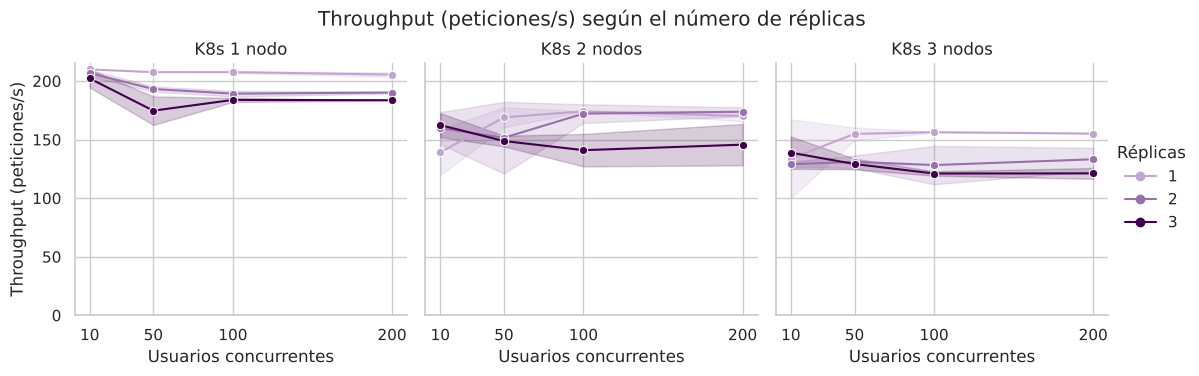

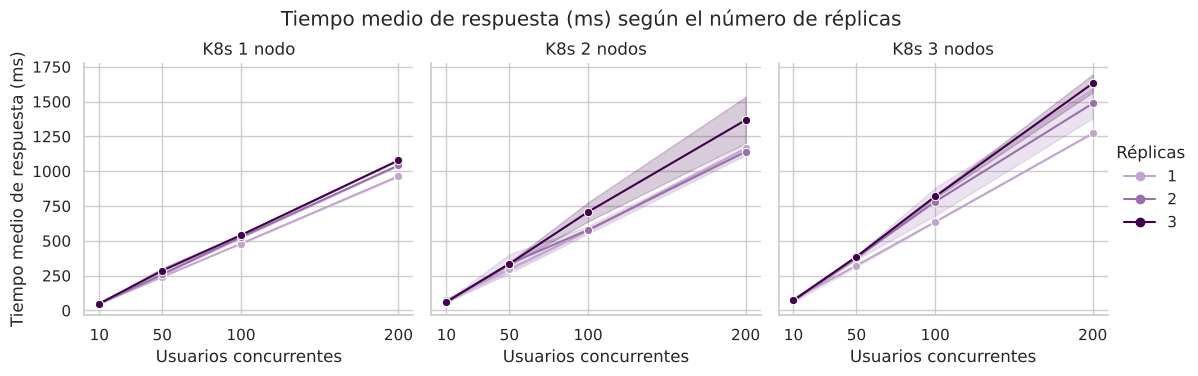

In [12]:
k8s = corridas[corridas.escenario != "Docker Compose"].copy()
k8s["escenario"] = k8s.escenario.cat.remove_unused_categories()
COLOR_REPLICAS = {1: "#c2a5cf", 2: "#9970ab", 3: "#40004b"}

for metrica, titulo in [("throughput", "Throughput (peticiones/s)"),
                        ("t_medio", "Tiempo medio de respuesta (ms)")]:
    g = sns.relplot(data=k8s, x="usuarios", y=metrica, hue="replicas", col="escenario",
                    kind="line", marker="o", errorbar="sd", palette=COLOR_REPLICAS,
                    height=3.6, aspect=1.05, facet_kws={"sharey": True})
    g.set_axis_labels("Usuarios concurrentes", titulo)
    g.set_titles("{col_name}")
    g.legend.set_title("Réplicas")
    g.set(xticks=[10, 50, 100, 200])
    if metrica == "throughput":
        g.set(ylim=(0, None))
    g.figure.suptitle(f"{titulo} según el número de réplicas", y=1.04)
    plt.show()

### 7.3 Efecto del número de nodos

Misma comparación, pero dejando fijas las réplicas y cambiando los nodos.

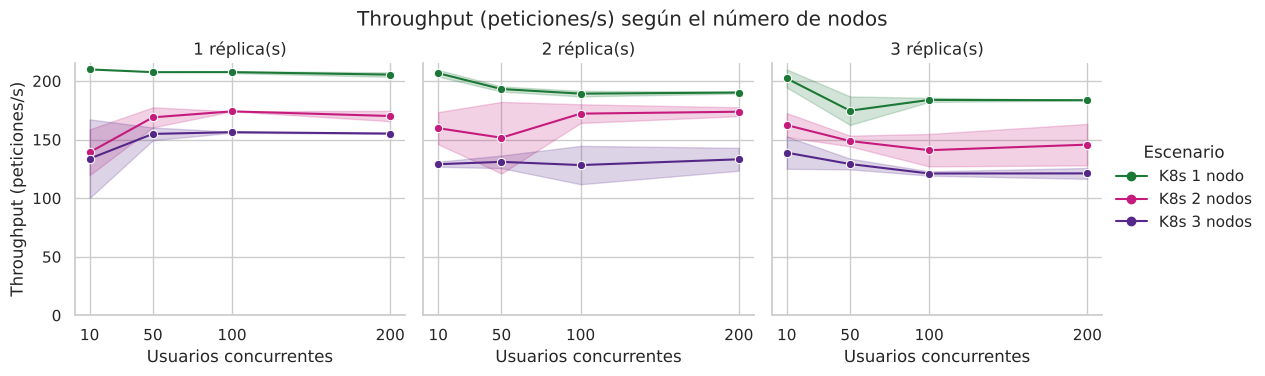

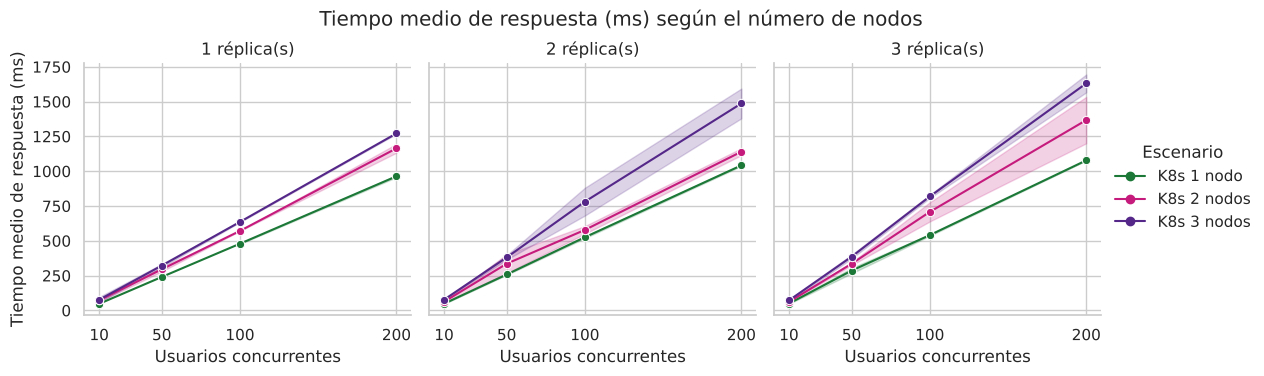

In [13]:
COLOR_NODOS = {"K8s 1 nodo": "#1b7837", "K8s 2 nodos": "#c51b7d", "K8s 3 nodos": "#542788"}

for metrica, titulo in [("throughput", "Throughput (peticiones/s)"),
                        ("t_medio", "Tiempo medio de respuesta (ms)")]:
    g = sns.relplot(data=k8s, x="usuarios", y=metrica, hue="escenario", col="replicas",
                    kind="line", marker="o", errorbar="sd", palette=COLOR_NODOS,
                    height=3.6, aspect=1.05)
    g.set_axis_labels("Usuarios concurrentes", titulo)
    g.set_titles("{col_name} réplica(s)")
    g.legend.set_title("Escenario")
    g.set(xticks=[10, 50, 100, 200])
    if metrica == "throughput":
        g.set(ylim=(0, None))
    g.figure.suptitle(f"{titulo} según el número de nodos", y=1.04)
    plt.show()

### 7.4 Las nueve configuraciones de Kubernetes con 100 usuarios

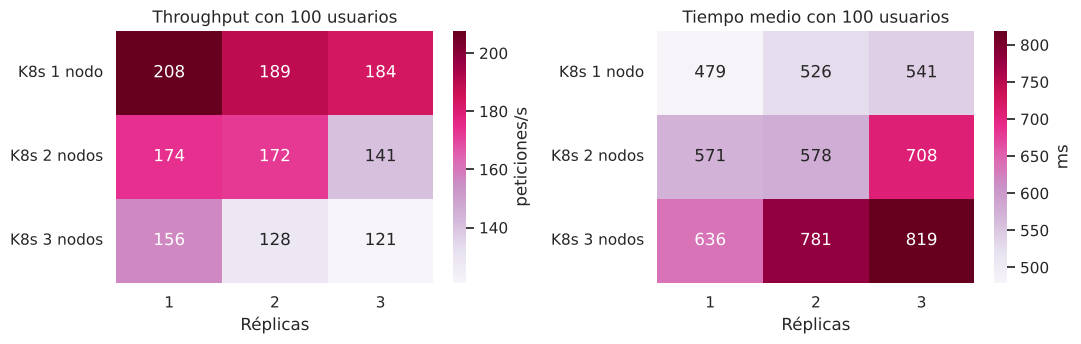

Cambio del throughput frente a K8s 1 nodo con 1 réplica (%)


replicas,1,2,3
escenario,,,
K8s 1 nodo,0.0,-8.8,-11.4
K8s 2 nodos,-16.1,-17.1,-32.1
K8s 3 nodos,-24.7,-38.2,-41.7


In [14]:
cien = resumen.xs(100, level="usuarios").drop("Docker Compose", level="escenario", errors="ignore")
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.heatmap(cien.throughput.unstack("replicas"), annot=True, fmt=".0f", cmap="PuRd",
            cbar_kws={"label": "peticiones/s"}, ax=ejes[0])
ejes[0].set_title("Throughput con 100 usuarios")
sns.heatmap(cien.t_medio.unstack("replicas"), annot=True, fmt=".0f", cmap="PuRd",
            cbar_kws={"label": "ms"}, ax=ejes[1])
ejes[1].set_title("Tiempo medio con 100 usuarios")
for ax in ejes:
    ax.set_xlabel("Réplicas"); ax.set_ylabel("")
plt.tight_layout()
plt.show()

base = cien.loc[("K8s 1 nodo", 1), "throughput"]
cambio = (100 * (cien.throughput / base - 1)).unstack("replicas").round(1)
print("Cambio del throughput frente a K8s 1 nodo con 1 réplica (%)")
display(cambio)

### 7.5 Docker Compose frente a Kubernetes

Docker Compose solo se probó con 1 réplica, así que se compara con las configuraciones de Kubernetes que también tienen 1 réplica, en las cuatro cargas. Los límites de CPU y memoria son los mismos en los dos casos.

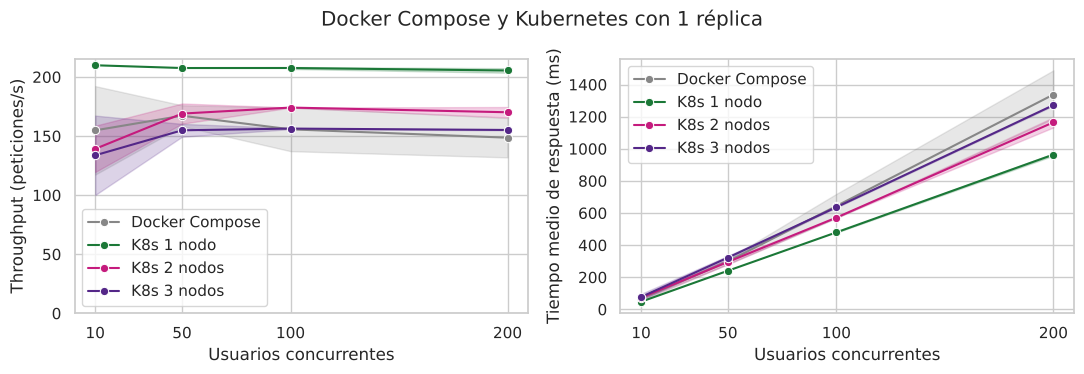

Throughput (peticiones/s) con 1 réplica


usuarios,10,50,100,200
escenario,,,,
Docker Compose,154.8,167.2,155.7,148.6
K8s 1 nodo,209.9,207.6,207.6,205.5
K8s 2 nodos,139.1,169.0,174.1,170.1
K8s 3 nodos,133.7,154.9,156.3,155.2


Docker Compose frente a K8s 1 nodo (%)


usuarios,10,50,100,200
Compose,154.8,167.2,155.7,148.6
K8s 1 nodo,209.9,207.6,207.6,205.5
diferencia_pct,-26.2,-19.4,-25.0,-27.7


In [15]:
una = corridas[corridas.replicas == 1].copy()
una["escenario"] = una.escenario.cat.remove_unused_categories()
COLOR_UNA = {"Docker Compose": "#878787", "K8s 1 nodo": "#1b7837",
             "K8s 2 nodos": "#c51b7d", "K8s 3 nodos": "#542788"}

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
for eje, metrica, titulo in [(ejes[0], "throughput", "Throughput (peticiones/s)"),
                             (ejes[1], "t_medio", "Tiempo medio de respuesta (ms)")]:
    sns.lineplot(data=una, x="usuarios", y=metrica, hue="escenario", marker="o",
                 errorbar="sd", palette=COLOR_UNA, ax=eje)
    eje.set(xlabel="Usuarios concurrentes", ylabel=titulo, xticks=[10, 50, 100, 200])
    eje.legend(title="")
ejes[0].set_ylim(0, None)
fig.suptitle("Docker Compose y Kubernetes con 1 réplica")
plt.tight_layout()
plt.show()

prom = una.groupby(["escenario", "usuarios"], observed=True)[["throughput", "t_medio"]].mean()
print("Throughput (peticiones/s) con 1 réplica")
display(prom.throughput.unstack("usuarios").round(1))

ref = prom.throughput.xs("K8s 1 nodo")
compose = prom.throughput.xs("Docker Compose")
print("Docker Compose frente a K8s 1 nodo (%)")
display(pd.DataFrame({"Compose": compose.round(1), "K8s 1 nodo": ref.round(1),
                      "diferencia_pct": (100 * (compose / ref - 1)).round(1)}).T)

In [16]:
# Las dos repeticiones de Docker Compose por separado
display(corridas[corridas.escenario == "Docker Compose"]
        .pivot_table(index="corrida", columns="usuarios", values="throughput", observed=True)
        .round(1).rename_axis(index="repetición"))

usuarios,10,50,100,200
repetición,,,,
1,181.3,160.9,168.8,160.4
2,128.3,173.5,142.6,136.8


### 7.6 Comparación por endpoint

Tiempo medio de cada tipo de petición con 100 usuarios. La consulta paginada devuelve unos 3,9 KB y hace dos consultas a MySQL (la página y el `COUNT(*)`). La consulta por ISBN devuelve unos 0,4 KB y hace una sola búsqueda por llave primaria.

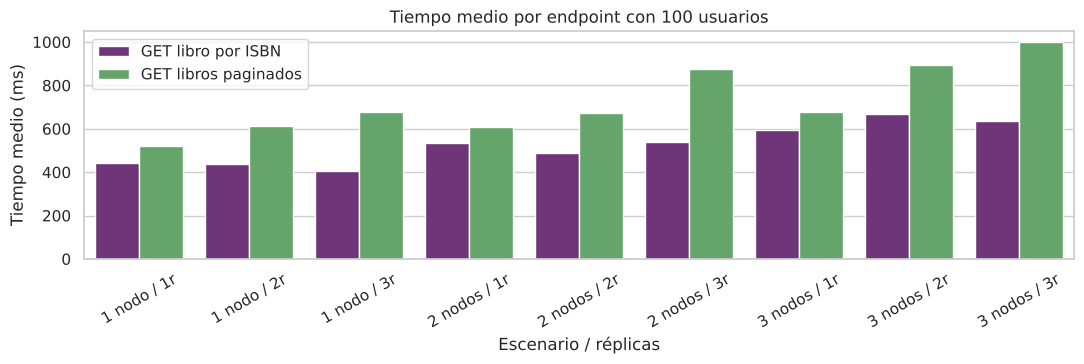

endpoint              GET libro por ISBN  GET libros paginados
escenario   replicas                                          
K8s 1 nodo  1                      440.0                 519.0
            2                      439.0                 612.0
            3                      403.0                 679.0
K8s 2 nodos 1                      535.0                 608.0
            2                      486.0                 671.0
            3                      541.0                 875.0
K8s 3 nodos 1                      593.0                 679.0
            2                      669.0                 894.0
            3                      636.0                1001.0

In [17]:
e100 = endpoints[(endpoints.usuarios == 100) & (endpoints.escenario != "Docker Compose")].copy()
e100["config"] = e100.escenario.astype(str).str.replace("K8s ", "") + " / " + e100.replicas.astype(str) + "r"
orden_config = [f"{n} / {r}r" for n in ["1 nodo", "2 nodos", "3 nodos"] for r in (1, 2, 3)]
plt.figure(figsize=(11, 3.8))
sns.barplot(data=e100, x="config", y="t_medio", hue="endpoint", order=orden_config,
            palette=["#762a83", "#5aae61"], errorbar=None)
plt.xlabel("Escenario / réplicas")
plt.ylabel("Tiempo medio (ms)")
plt.title("Tiempo medio por endpoint con 100 usuarios")
plt.xticks(rotation=30)
plt.legend(title="")
plt.tight_layout()
plt.show()

display(e100.groupby(["escenario", "replicas", "endpoint"], observed=True).t_medio.mean()
        .unstack("endpoint").round(0))

### 7.7 Estabilidad de la carga durante una prueba

Throughput cada 5 segundos en dos pruebas de 100 usuarios: la mejor y la peor configuración. La línea vertical marca el fin de la subida de usuarios.

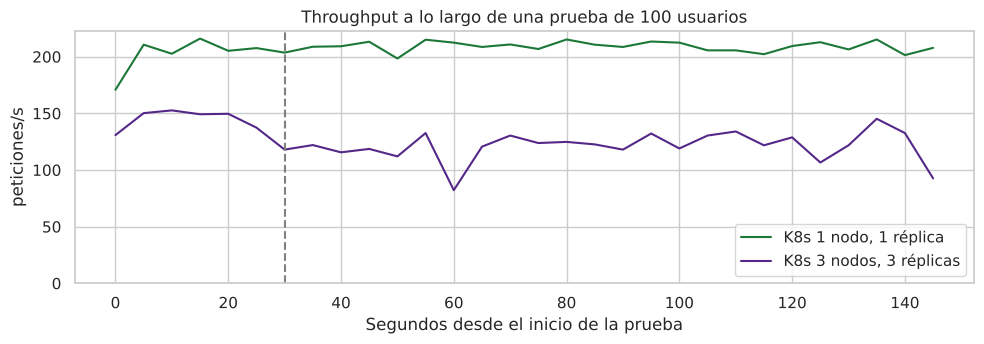

In [18]:
plt.figure(figsize=(10, 3.6))
for archivo, etiqueta, color in [("k8s1n_1rep_100u_r1_vm.csv", "K8s 1 nodo, 1 réplica", "#1b7837"),
                                 ("k8s3n_3rep_100u_r1_vm.csv", "K8s 3 nodos, 3 réplicas", "#542788")]:
    if archivo in series:
        s = series[archivo]
        plt.plot(s.index * 5, s.values, label=etiqueta, color=color)
plt.axvline(RAMPUP_S, color="gray", linestyle="--")
plt.xlabel("Segundos desde el inicio de la prueba")
plt.ylabel("peticiones/s")
plt.title("Throughput a lo largo de una prueba de 100 usuarios")
plt.ylim(0, None)
plt.legend()
plt.tight_layout()
plt.show()

### 7.8 Comprobación con la ley de Little

En una prueba sin pausas entre peticiones, los usuarios, el throughput y el tiempo de respuesta cumplen aproximadamente **usuarios ≈ throughput × tiempo medio** (ley de Little). Si se cumple, el tiempo de respuesta que crece con la carga es tiempo de espera en cola: el sistema ya está atendiendo todo lo que puede y las peticiones nuevas solo esperan su turno.

In [19]:
little = resumen.reset_index()
little["usuarios_estimados"] = little.throughput * little.t_medio / 1000
display(little.pivot_table(index=["escenario", "replicas"], columns="usuarios",
                           values="usuarios_estimados", observed=True).round(0))

usuarios                  10    50     100    200
escenario      replicas                          
Docker Compose 1         10.0  50.0  100.0  199.0
K8s 1 nodo     1         10.0  50.0  100.0  198.0
               2         10.0  50.0  100.0  198.0
               3         10.0  50.0   99.0  198.0
K8s 2 nodos    1         10.0  50.0   99.0  198.0
               2         10.0  51.0  100.0  198.0
               3         10.0  50.0  100.0  199.0
K8s 3 nodos    1         10.0  50.0   99.0  197.0
               2         10.0  50.0  100.0  198.0
               3         10.0  50.0   99.0  198.0

## 8. Análisis comparativo

### 8.1 La aplicación llega a su máximo desde los 10 usuarios

En todas las configuraciones el throughput casi no cambia entre 10 y 200 usuarios. Con 1 nodo y 1 réplica, por ejemplo, se atienden unas 210 peticiones por segundo con 10 usuarios y unas 206 con 200. Lo que sí cambia es el tiempo medio, que pasa de unos 48 ms a unos 964 ms, casi en proporción a los usuarios.

La tabla de la sección 7.8 confirma la explicación: throughput × tiempo medio da prácticamente el número de usuarios en todos los casos. El sistema ya trabaja a su máximo con 10 usuarios, y de ahí en adelante los usuarios extra solo hacen más larga la cola. Por eso, para comparar configuraciones, el throughput es la métrica más clara: muestra la capacidad de cada configuración, mientras que el tiempo medio depende sobre todo de cuántos usuarios esperan.

### 8.2 Más réplicas no aumentan la capacidad

Se esperaba que más réplicas atendieran más peticiones. Pasó lo contrario. Con 100 usuarios:

| Escenario | 1 réplica | 2 réplicas | 3 réplicas | Cambio de 1 a 3 |
|---|---|---|---|---|
| 1 nodo | 207,6 | 189,2 | 183,9 | −11 % |
| 2 nodos | 174,1 | 172,2 | 141,0 | −19 % |
| 3 nodos | 156,3 | 128,2 | 121,0 | −23 % |

*(peticiones por segundo)*

Una sola réplica, limitada a 0,5 CPU, ya atiende unas 208 peticiones por segundo. Con 3 réplicas el backend tiene en total 1,5 CPU, tres veces más, y el resultado baja. Eso indica que el límite no está en el backend sino en algo que todas las réplicas comparten: la base de datos y el procesador físico del computador.

Hay dos efectos que explican la caída:

- **En un solo nodo**, las réplicas y MySQL se reparten los 2 núcleos de vm1. Cada réplica es una máquina virtual de Java completa, con su propio recolector de basura y sus propios hilos. Agregar réplicas suma procesos compitiendo por la misma CPU sin agregar CPU.
- **Más conexiones a la misma base.** Cada réplica abre su propio grupo de 10 conexiones a MySQL. Con 3 réplicas son 30 conexiones contra una base limitada a 1 CPU, y más peticiones simultáneas sobre MySQL la hacen más lenta, no más rápida.

La sección 7.6 apoya la segunda idea. La consulta paginada, que hace dos consultas a MySQL, empeora con las réplicas mucho más que la consulta por ISBN, que es una búsqueda simple. En 3 nodos, la paginada pasa de unos 680 a unos 1.000 ms al ir de 1 a 3 réplicas, mientras que la de ISBN casi no cambia.

### 8.3 Más nodos tampoco ayudan; cada nodo agregado empeora el resultado

Con la misma cantidad de réplicas, pasar de 1 a 2 y a 3 nodos bajó el throughput en todos los casos:

- Con 1 réplica: de 207,6 a 174,1 y a 156,3 peticiones por segundo (−16 % y −25 %).
- Con 3 réplicas: de 183,9 a 141,0 y a 121,0 (−23 % y −34 %).

La peor configuración (3 nodos, 3 réplicas) atiende un 42 % menos que la mejor (1 nodo, 1 réplica), y su tiempo medio con 100 usuarios es un 71 % mayor (819 ms frente a 479 ms).

Las razones:

- **Los nodos no son máquinas reales distintas.** Las tres VM corren en el mismo computador. Un nodo nuevo no trae procesador nuevo: trae otra VM con su propio Kubernetes (kubelet, Calico, containerd) gastando CPU del mismo procesador. Sin carga, vm2 y vm3 ya usaban cerca de 10 % de CPU cada una.
- **La red entre nodos agrega pasos.** JMeter siempre envía las peticiones a vm1 y MySQL está en vm1. Si la réplica que atiende está en vm2 o vm3, cada petición cruza la red virtual cuatro veces (vm1 → réplica → MySQL en vm1 → réplica → vm1). Cada cruce pasa por la red de Calico, que encapsula los paquetes, y por la red virtual de VirtualBox. Todo eso también consume CPU del mismo computador.

En un nodo, en cambio, todo el recorrido se queda dentro de vm1, y por eso es el escenario más rápido.

### 8.4 Docker Compose frente a Kubernetes

Se esperaba que Docker Compose y Kubernetes de 1 nodo dieran resultados parecidos, porque usan la misma máquina (vm1), la misma imagen y los mismos límites de CPU y memoria. No fue así. Con las cuatro cargas, Docker Compose atendió entre 19 % y 28 % menos peticiones por segundo que Kubernetes de 1 nodo con 1 réplica:

| Usuarios | Docker Compose | K8s 1 nodo | Diferencia |
|---|---|---|---|
| 10 | 154,8 | 209,9 | −26 % |
| 50 | 167,2 | 207,6 | −19 % |
| 100 | 155,7 | 207,6 | −25 % |
| 200 | 148,6 | 205,5 | −28 % |

*(peticiones por segundo, 1 réplica)*

El tiempo medio sigue el mismo patrón: con 200 usuarios fue de 1.337 ms en Compose y de 964 ms en Kubernetes. En capacidad, Compose quedó al nivel de Kubernetes con 2 o 3 nodos, no al de 1 nodo. Ni siquiera la mejor repetición de Compose (181 peticiones por segundo con 10 usuarios) alcanzó a ninguna de las de Kubernetes de 1 nodo, que estuvieron todas entre 204 y 210.

No hay datos de monitorización para confirmar la causa, pero hay dos explicaciones posibles:

- **Cómo entra el tráfico.** En Compose el puerto 8081 se publica con `docker-proxy`, un proceso que recibe cada conexión y la reenvía al contenedor. Ese proceso corre fuera del límite de 0,5 CPU del backend y compite con todo lo demás en vm1. En Kubernetes, el NodePort se resuelve con reglas de red del kernel (kube-proxy con iptables), que no pasan por un proceso intermedio.
- **Las pruebas de Compose se repitieron en otro momento.** Las de Kubernetes se hicieron seguidas, mientras que las de Compose se completaron después. Si el computador tenía otra carga en ese momento, eso afecta el resultado. La diferencia grande entre las dos repeticiones de Compose (181 y 128 peticiones por segundo con 10 usuarios) apunta en esa dirección.

Lo que sí se puede afirmar es que, en este montaje, Kubernetes no le agregó un costo visible a la aplicación frente a Compose; con 1 nodo incluso rindió más. La ventaja que se pierde en Kubernetes aparece al agregar nodos, por las razones de la sección 8.3.

### 8.5 Variación entre repeticiones y errores

- No hubo errores en ninguna prueba válida, ni siquiera con 200 usuarios. Las peticiones tardaban más, pero todas se atendieron.
- Las repeticiones de una misma configuración dieron valores muy parecidos (pocas peticiones por segundo de diferencia), salvo las pruebas de 10 usuarios con 2 y 3 nodos y las de Docker Compose. Las de 10 usuarios fueron las primeras de cada serie, y la variación probablemente se debe a réplicas recién arrancadas. En Compose la segunda repetición salió más baja en tres de las cuatro cargas, con diferencias de hasta 53 peticiones por segundo.
- La gráfica de la sección 7.7 muestra que, pasada la subida de usuarios, el throughput se mantiene estable durante toda la prueba, sin caídas.

## 9. Conclusiones

1. **La capacidad de la aplicación quedó limitada por los recursos compartidos, no por el backend.** Una réplica con medio núcleo ya llegaba al máximo de unas 200 peticiones por segundo. Desde ese punto, más usuarios solo aumentaron la cola y el tiempo de respuesta.

2. **El escalado horizontal del backend no mejoró el rendimiento en este montaje.** Con 3 réplicas el throughput bajó entre 11 % y 23 % según el número de nodos. Escalar solo sirve cuando la parte que se escala es la que limita, y aquí el límite estaba en la base de datos, que no se escala, y en el procesador físico, que todas las VM comparten.

3. **Agregar nodos empeoró el rendimiento.** Con 2 nodos el throughput fue entre 9 % y 23 % menor que con 1, y con 3 nodos entre 25 % y 34 % menor. Como los nodos son VM en un mismo computador, cada nodo agrega trabajo (Kubernetes, red, virtualización) sin agregar procesador, y obliga a las peticiones a cruzar la red virtual hasta la base.

4. **La configuración más eficiente fue Kubernetes de 1 nodo con 1 réplica**, con unas 208 peticiones por segundo en todas las cargas. Docker Compose, en la misma máquina y con los mismos límites, atendió entre 19 % y 28 % menos. Kubernetes no fue una capa costosa en este montaje; lo que bajó el rendimiento fue repartir la aplicación entre más réplicas y más nodos sobre el mismo hardware.

5. **La aplicación fue estable:** 0 % de errores en todas las pruebas válidas y throughput constante durante cada prueba.

6. **Los resultados dependen del entorno.** En un clúster con nodos en computadores físicos distintos, y con una base de datos que no sea el cuello de botella, es de esperar que más réplicas y más nodos sí aumenten la capacidad. Este experimento muestra el caso contrario: escalar sin hardware nuevo y con una base compartida no da más rendimiento y agrega costos.

## 10. Recomendaciones

**Sobre la infraestructura**

- Usar nodos en computadores físicos distintos, o en máquinas de nube, para que cada nodo agregue CPU real. Es la condición para que el escalado horizontal se pueda observar.
- Ejecutar JMeter en un computador diferente al de los nodos, para que la generación de carga no compita con la aplicación.
- Repartir las peticiones de JMeter entre las IP de todos los nodos, o usar un balanceador o Ingress, para que vm1 no sea la única puerta de entrada.

**Sobre la aplicación y la base de datos**

- Quitar el `SELECT COUNT(*)` del listado paginado (usar `Slice` en lugar de `Page` en Spring Data). La mitad de las peticiones haría la mitad de trabajo en MySQL.
- Ajustar el grupo de conexiones según las réplicas, para que el total de conexiones no sature la base.
- Darle a MySQL más CPU, o un nodo propio, ya que es el componente que todas las réplicas comparten.
- Para datos que se leen mucho y cambian poco, como un catálogo, agregar una cache en el backend o réplicas de lectura de MySQL. Así las réplicas del backend dejan de depender por completo de una sola base.

**Sobre la metodología**

- Monitorear CPU y memoria de nodos y pods durante cada prueba (Prometheus y Grafana, o al menos `kubectl top`), para confirmar con datos dónde está el cuello de botella.
- Repetir Docker Compose y Kubernetes de 1 nodo en la misma sesión, una detrás de la otra, para confirmar si la diferencia entre ambos se mantiene. Probar Compose con `userland-proxy` desactivado en Docker ayudaría a saber si `docker-proxy` es la causa.
- Hacer 3 o más repeticiones por configuración y registrar en qué nodo queda cada réplica.

## 11. Limitaciones

- Las cuatro VM, incluida la de JMeter, corrieron en el mismo computador. JMeter y la aplicación competían por el mismo procesador, y los nodos no aportaron CPU real.
- No hay datos de monitorización guardados durante las pruebas; las explicaciones de los cuellos de botella se apoyan en los tiempos medidos y en observaciones puntuales de `kubectl top`.
- Las pruebas de Docker Compose se completaron en una sesión distinta a las de Kubernetes y variaron bastante entre repeticiones, así que la comparación entre los dos tiene menos certeza que las comparaciones dentro de Kubernetes.
- Las pruebas de 10 y 50 usuarios con 1 nodo y 1 réplica tienen una sola repetición válida; la primera se descartó (ver sección 6).